# 02 · RescueNet — Training & Validation Pipeline

**Inputs:** output of notebook 01 (`Add Input → Your Work`). **Accelerator:** GPU T4 ×2 or P100 — training uses **one GPU** (see v3 note). **Internet:** on (for `segmentation-models-pytorch` + ImageNet weights).

**Setup**
- Model: DeepLabV3+ with ImageNet-pretrained ResNet-50 encoder (`segmentation_models_pytorch`; swap `arch`/`encoder` in `CFG`).
- Train: random-resized 512×512 crops from the 1024×768 images (zoom ≈ 0.7–1.4×), flips, 90° rotations, light colour jitter.
- Val: full 1024×768 images — same scale as training.
- Loss: weighted cross-entropy (median-frequency weights from notebook 01) + Dice.
- AdamW, linear warm-up → cosine decay (per step), mixed precision, gradient clipping, early stopping on val mIoU.

**v3 – one GPU instead of `DataParallel`.** With `DataParallel` on T4 ×2, the main process gained ~10 GB of system RAM per epoch and Kaggle killed the kernel in epoch 3. Training now runs on a single GPU (`multi_gpu=False`). RAM is checked every 50 steps; if it passes `ram_limit_pct`, the run stops cleanly and can be resumed.

**Memory & time safeguards (v2)**
- Loader workers send **uint8** images/masks (4–8× less RAM / shared memory than float32/int64); normalisation happens on the GPU.
- Fewer workers, validation workers are not kept alive between epochs, and memory is released after every epoch. RAM use and data-vs-compute time are printed each epoch.
- **Time budget:** training stops cleanly before Kaggle's 12 h limit (`time_budget_hours`).
- **Resume:** if a `last_checkpoint.pth` from an earlier run is attached as input, training continues from it.

**Outputs (`/kaggle/working`)**: `best_model.pth`, `last_checkpoint.pth`, `history.csv`, `training_config.json`, plus copies of `dataset_info.json` / `manifest.csv` so notebook 03 has everything.

In [1]:
try:
    import segmentation_models_pytorch as smp
except ImportError:
    !pip install -q segmentation-models-pytorch
    import segmentation_models_pytorch as smp
print("smp", smp.__version__)

smp 0.6.0


In [2]:
import os, gc, json, math, time, random, shutil, tarfile, ctypes, warnings
from pathlib import Path

NOTEBOOK_START = time.time()

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
cv2.setNumThreads(0)
cv2.ocl.setUseOpenCL(False)

N_CPU = os.cpu_count() or 2
CFG = dict(
    arch="DeepLabV3Plus",          # Unet, UnetPlusPlus, FPN, PSPNet, DeepLabV3Plus ...
    encoder="resnet50",            # resnet34 (faster), efficientnet-b3, tu-convnext_tiny ...
    encoder_weights="imagenet",
    crop_size=512,
    batch_size=6,                  # one T4 (15 GB); lower to 4 on 'CUDA out of memory'
    val_batch_size=2,
    epochs=30,
    lr=3e-4,
    weight_decay=1e-4,
    warmup_epochs=1,
    min_lr_ratio=0.01,
    ce_weight=1.0,
    dice_weight=1.0,
    class_weight_key="median_clipped",   # median_clipped | inv_sqrt | none
    patience=8,
    grad_clip=1.0,
    amp=True,
    channels_last=True,            # faster convolutions on T4 tensor cores
    multi_gpu=False,               # nn.DataParallel leaked ~10 GB RAM/epoch on Kaggle - keep False
    ram_limit_pct=88,              # stop cleanly (resumable) if system RAM use goes above this
    num_workers=max(1, min(4, N_CPU - 1)),
    val_num_workers=2,
    time_budget_hours=11.0,        # Kaggle GPU sessions stop at 12 h
    resume=True,                   # continue from an attached last_checkpoint.pth if one exists
    seed=42,
)
WORK_DIR = Path("/kaggle/working")
DATA_DIR = Path("/tmp/rescuenet_resized")

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.benchmark = True
seed_everything(CFG["seed"])

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
N_GPU = torch.cuda.device_count() if CFG["multi_gpu"] else min(1, torch.cuda.device_count())
print("Device:", DEVICE, "| GPUs used:", N_GPU, [torch.cuda.get_device_name(i) for i in range(N_GPU)])
print("CPUs:", N_CPU, "| train workers:", CFG["num_workers"], "| val workers:", CFG["val_num_workers"])

def free_memory():
    gc.collect()
    try:
        ctypes.CDLL("libc.so.6").malloc_trim(0)   # hand freed heap memory back to the OS
    except Exception:
        pass
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def ram_pct():
    try:
        import psutil
        return psutil.virtual_memory().percent
    except Exception:
        return 0.0

def ram_report():
    try:
        import psutil
        vm = psutil.virtual_memory()
        main = psutil.Process().memory_info().rss
        shm = shutil.disk_usage("/dev/shm").used if os.path.exists("/dev/shm") else 0
        gpu = " | ".join(f"GPU{i} peak {torch.cuda.max_memory_allocated(i) / 1e9:.1f} GB" for i in range(N_GPU))
        return (f"RAM {vm.used / 1e9:.1f}/{vm.total / 1e9:.1f} GB used | main proc {main / 1e9:.1f} GB | "
                f"/dev/shm {shm / 1e9:.2f} GB" + (f" | {gpu}" if gpu else ""))
    except Exception as e:
        return f"(RAM report unavailable: {e})"

print(ram_report())

Device: cuda:0 | GPUs used: 1 ['Tesla T4']
CPUs: 4 | train workers: 3 | val workers: 2
RAM 1.4/33.7 GB used | main proc 0.9 GB | /dev/shm 0.00 GB | GPU0 peak 0.0 GB


## 1. Load notebook-01 outputs and unpack the resized data

In [3]:
def find_one(name, roots=("/kaggle/working", "/kaggle/input")):
    for r in roots:
        if Path(r).exists():
            hits = sorted(Path(r).rglob(name))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"{name} not found - attach notebook 01's output as an input.")

info_path = find_one("dataset_info.json")
info = json.loads(info_path.read_text())
manifest = pd.read_csv(find_one("manifest.csv"), dtype={"id": str})

if not (DATA_DIR / "train" / "images").exists():
    tar_path = find_one(info["tar_name"])
    print("Extracting", tar_path, "...")
    t0 = time.time()
    with tarfile.open(tar_path) as t:
        t.extractall(DATA_DIR.parent)
    print(f"done in {time.time() - t0:.0f}s")

CLASSES = info["classes"]; NUM_CLASSES = info["num_classes"]
PALETTE = np.array(info["palette"], dtype=np.uint8)
MEAN, STD = info["imagenet_mean"], info["imagenet_std"]     # pretrained encoder -> ImageNet stats
IMG_W, IMG_H = info["image_size_wh"]

train_df = manifest[manifest.split == "train"].reset_index(drop=True)
val_df = manifest[manifest.split == "val"].reset_index(drop=True)
missing = [p for p in pd.concat([train_df, val_df]).image if not (DATA_DIR / p).exists()]
assert not missing, f"{len(missing)} files missing after extraction"
print(f"train {len(train_df)} | val {len(val_df)} | classes {NUM_CLASSES} | image {IMG_W}x{IMG_H}")

for f in ["dataset_info.json", "manifest.csv", "class_weights.npz"]:
    try:
        src = find_one(f)
        if src.parent != WORK_DIR:
            shutil.copy(src, WORK_DIR / f)
    except FileNotFoundError:
        pass

Extracting /kaggle/input/notebooks/hisambhav/rescuenet-preprocessing/rescuenet_resized.tar ...
done in 16s
train 3595 | val 449 | classes 12 | image 1024x768


## 2. Datasets, augmentation, loaders
Workers return **uint8** tensors (image `3×H×W`, mask `H×W`). Converting to float, normalising and casting masks to `long` is done on the GPU in `to_device()`. This keeps the batches passed between processes 4–8× smaller, which is what was filling RAM before.

599 train steps/epoch | 225 val steps
batch: (6, 3, 512, 512) torch.uint8 | masks: (6, 512, 512) torch.uint8 | labels: [1, 2, 3, 4, 5, 7, 8, 9, 10, 11]


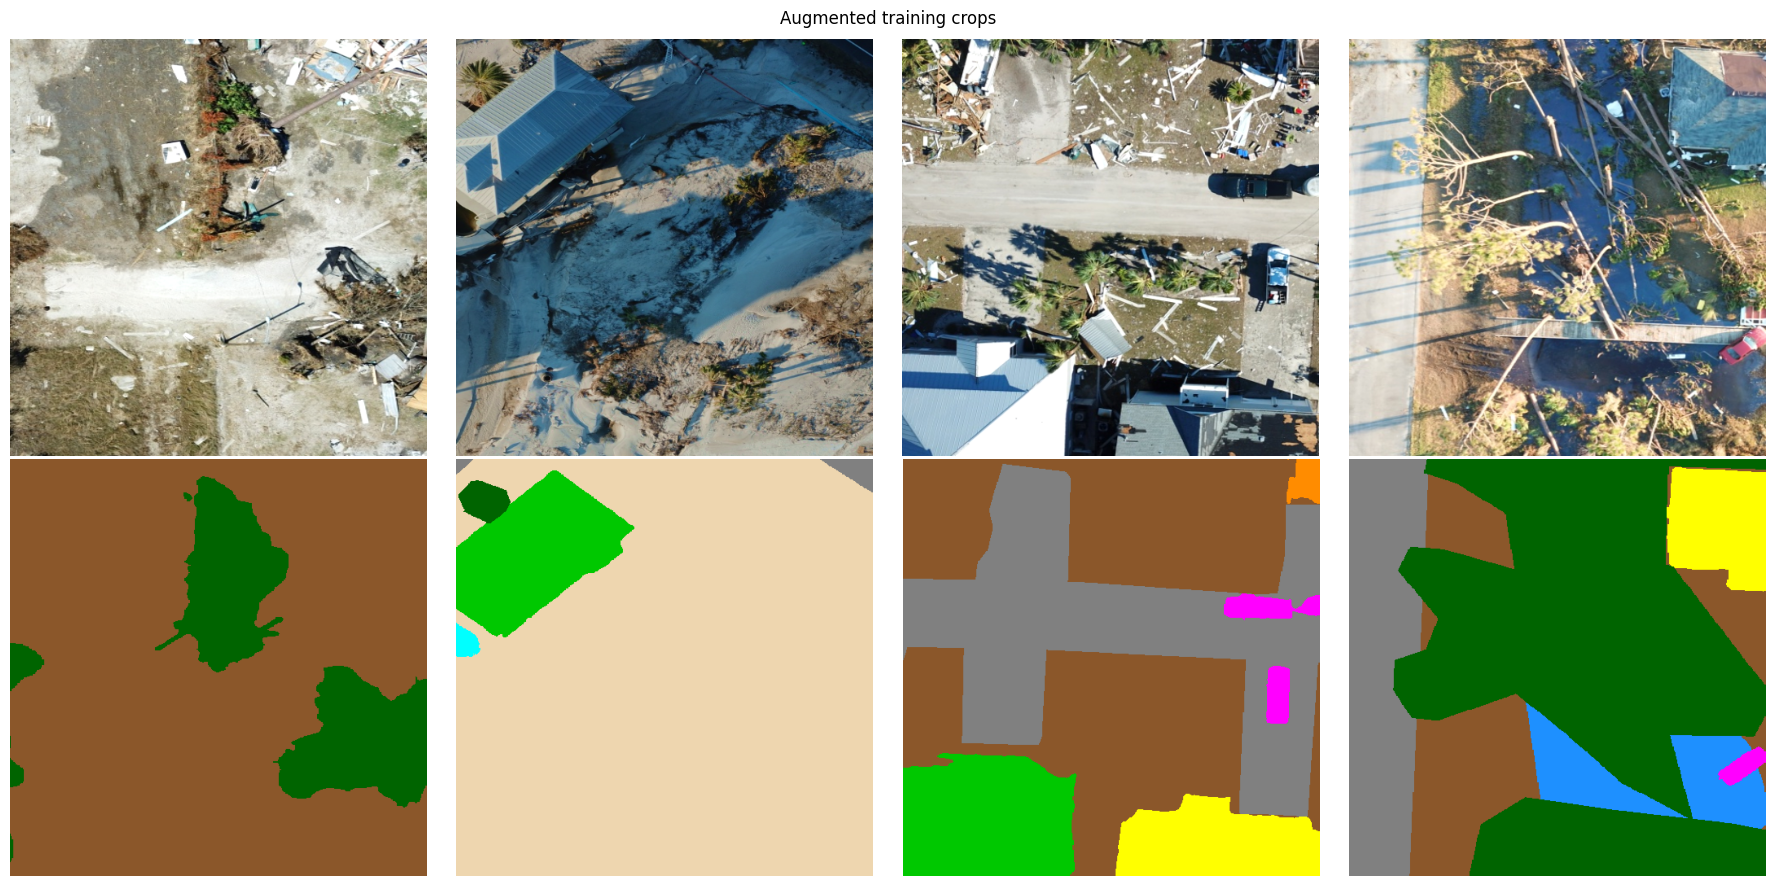

In [4]:
def random_resized_crop(size, **kw):
    try:
        return A.RandomResizedCrop(size=(size, size), **kw)          # albumentations >= 1.4
    except TypeError:
        return A.RandomResizedCrop(height=size, width=size, **kw)    # older versions

S = CFG["crop_size"]
# 512x512 is ~33% of a 1024x768 image; area range 0.17-0.65 gives ~0.7x-1.4x zoom around native scale
train_tf = A.Compose([
    random_resized_crop(S, scale=(0.17, 0.65), ratio=(0.75, 1.333), p=1.0),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(0.2, 0.2, p=0.5),
    A.HueSaturationValue(10, 15, 10, p=0.3),
    ToTensorV2(),                  # uint8 stays uint8
])
val_tf = A.Compose([ToTensorV2()])   # full 1024x768, no resize

class SegDataset(Dataset):
    def __init__(self, frame, root, transform):
        # numpy string arrays instead of Python lists: avoids copy-on-write memory growth in workers
        self.images = np.array([str(Path(root) / p) for p in frame["image"]])
        self.masks = np.array([str(Path(root) / p) for p in frame["mask"]])
        self.transform = transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(str(self.images[i])), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(str(self.masks[i]), cv2.IMREAD_UNCHANGED)
        out = self.transform(image=img, mask=mask)
        return out["image"], out["mask"]          # uint8, uint8

MEAN_T = torch.tensor(MEAN, device=DEVICE).view(1, 3, 1, 1) * 255
STD_T = torch.tensor(STD, device=DEVICE).view(1, 3, 1, 1) * 255
MEM_FMT = torch.channels_last if CFG["channels_last"] else torch.contiguous_format

def to_device(x, y):
    x = x.to(DEVICE, non_blocking=True).float().sub_(MEAN_T).div_(STD_T).contiguous(memory_format=MEM_FMT)
    y = y.to(DEVICE, non_blocking=True).long()
    return x, y

nw, vnw = CFG["num_workers"], CFG["val_num_workers"]
train_loader = DataLoader(SegDataset(train_df, DATA_DIR, train_tf), batch_size=CFG["batch_size"], shuffle=True,
                          num_workers=nw, pin_memory=True, drop_last=True, persistent_workers=nw > 0,
                          prefetch_factor=2 if nw > 0 else None)
val_loader = DataLoader(SegDataset(val_df, DATA_DIR, val_tf), batch_size=CFG["val_batch_size"], shuffle=False,
                        num_workers=vnw, pin_memory=True, persistent_workers=False,
                        prefetch_factor=2 if vnw > 0 else None)
print(f"{len(train_loader)} train steps/epoch | {len(val_loader)} val steps")

xb, yb = next(iter(train_loader))
print("batch:", tuple(xb.shape), xb.dtype, "| masks:", tuple(yb.shape), yb.dtype, "| labels:", yb.unique().tolist())
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for i in range(min(4, len(xb))):
    axes[0, i].imshow(xb[i].permute(1, 2, 0).numpy()); axes[0, i].axis("off")
    axes[1, i].imshow(PALETTE[yb[i].numpy()]); axes[1, i].axis("off")
fig.suptitle("Augmented training crops"); plt.tight_layout(); plt.show()
del xb, yb; free_memory()

## 3. Model, loss, optimizer, schedule

In [5]:
model = smp.create_model(arch=CFG["arch"], encoder_name=CFG["encoder"], encoder_weights=CFG["encoder_weights"],
                         in_channels=3, classes=NUM_CLASSES)
model = model.to(DEVICE, memory_format=MEM_FMT)
if N_GPU > 1:
    model = nn.DataParallel(model)
unwrap = lambda m: m.module if isinstance(m, nn.DataParallel) else m
print(f"{CFG['arch']} / {CFG['encoder']}: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M params")

if CFG["class_weight_key"] == "none":
    class_w = None
else:
    class_w = torch.tensor(info["class_weights"][CFG["class_weight_key"]], dtype=torch.float32, device=DEVICE)
    print("class weights:", {c: round(float(w), 3) for c, w in zip(CLASSES, class_w.cpu())})

class ComboLoss(nn.Module):
    def __init__(self, weight):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=weight)
        self.dice = smp.losses.DiceLoss(mode="multiclass", from_logits=True)
    def forward(self, logits, target):
        logits = logits.float()
        return CFG["ce_weight"] * self.ce(logits, target) + CFG["dice_weight"] * self.dice(logits, target)

criterion = ComboLoss(class_w)
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])

total_steps = CFG["epochs"] * len(train_loader)
warmup_steps = CFG["warmup_epochs"] * len(train_loader)
def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    p = min(1.0, (step - warmup_steps) / max(1, total_steps - warmup_steps))
    return CFG["min_lr_ratio"] + (1 - CFG["min_lr_ratio"]) * 0.5 * (1 + math.cos(math.pi * p))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

use_amp = CFG["amp"] and DEVICE.type == "cuda"
try:
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

DeepLabV3Plus / resnet50: 26.7M params
class weights: {'Background': 0.753, 'Debris': 0.133, 'Water': 0.485, 'Building_No_Damage': 1.488, 'Building_Minor_Damage': 1.497, 'Building_Major_Damage': 2.343, 'Building_Total_Destruction': 2.732, 'Vehicle': 10.0, 'Road': 0.463, 'Tree': 0.179, 'Pool': 10.0, 'Sand': 0.224}


## 4. Metrics (confusion-matrix based)

In [6]:
@torch.no_grad()
def update_cm(cm, pred, target, n=NUM_CLASSES):
    k = (target >= 0) & (target < n)
    cm += torch.bincount(target[k] * n + pred[k], minlength=n * n).reshape(n, n)
    return cm

def scores_from_cm(cm):
    cm = cm.double()
    tp = cm.diag()
    iou = tp / (cm.sum(0) + cm.sum(1) - tp).clamp(min=1)
    valid = cm.sum(1) > 0                      # classes present in ground truth
    return {"miou": iou[valid].mean().item(), "pixel_acc": (tp.sum() / cm.sum()).item(),
            "iou": iou.cpu().numpy()}

## 5. Train / validate loops
`data_s` = time spent waiting for the DataLoader, `gpu_s` = time spent in forward/backward. If `data_s` is large, the CPU is the bottleneck.

In [7]:
class RamLimitHit(Exception):
    pass

def train_one_epoch(epoch):
    model.train()
    running, n, t_data, t_gpu = 0.0, 0, 0.0, 0.0
    pbar = tqdm(train_loader, desc=f"train {epoch}", leave=False, mininterval=30)
    t = time.perf_counter()
    for x, y in pbar:
        t_data += time.perf_counter() - t; t = time.perf_counter()
        x, y = to_device(x, y)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            logits = model(x)
        loss = criterion(logits, y)
        scaler.scale(loss).backward()
        if CFG["grad_clip"]:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(optimizer); scaler.update(); scheduler.step()
        x_bs = x.size(0)
        running += loss.item() * x_bs; n += x_bs
        del x, y, logits, loss
        t_gpu += time.perf_counter() - t; t = time.perf_counter()
        step = n // x_bs
        if step == 1 or step % 50 == 0:
            ram = ram_pct()
            pbar.set_postfix(loss=f"{running / n:.4f}", lr=f"{scheduler.get_last_lr()[0]:.2e}", ram=f"{ram:.0f}%")
            if ram > CFG["ram_limit_pct"]:
                raise RamLimitHit(f"system RAM at {ram:.0f}% (limit {CFG['ram_limit_pct']}%) at step {step}")
    return running / n, t_data, t_gpu

@torch.no_grad()
def validate():
    model.eval()
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.int64, device=DEVICE)
    running, n = 0.0, 0
    for x, y in tqdm(val_loader, desc="val", leave=False, mininterval=30):
        x, y = to_device(x, y)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            logits = model(x)
        running += criterion(logits, y).item() * x.size(0); n += x.size(0)
        update_cm(cm, logits.argmax(1), y)
        del x, y, logits
    s = scores_from_cm(cm)
    s["loss"] = running / n
    return s

## 6. Run training
If `CFG["resume"]` is on and a `last_checkpoint.pth` is found (in `/kaggle/working`, or attached as input from an earlier version of this notebook), model, optimizer, scheduler, history and best score are restored and training continues from the next epoch. Keep `CFG["epochs"]` the same as the earlier run so the learning-rate schedule lines up.

In [8]:
def save_ckpt(path, epoch, best_miou, extra=None):
    tmp = Path(str(path) + ".tmp")
    torch.save({"model_state": unwrap(model).state_dict(), "optimizer_state": optimizer.state_dict(),
                "scheduler_state": scheduler.state_dict(), "scaler_state": scaler.state_dict(),
                "epoch": epoch, "best_miou": best_miou, "cfg": CFG, "classes": CLASSES, **(extra or {})}, tmp)
    os.replace(tmp, path)          # never leaves a half-written checkpoint behind

history, best_miou, best_epoch, bad_epochs, start_epoch = [], -1.0, 0, 0, 1
if CFG["resume"]:
    try:
        ck_path = find_one("last_checkpoint.pth")
    except FileNotFoundError:
        ck_path = None
    if ck_path is not None:
        ck = torch.load(ck_path, map_location="cpu", weights_only=False)
        unwrap(model).load_state_dict(ck["model_state"])
        optimizer.load_state_dict(ck["optimizer_state"])
        scheduler.load_state_dict(ck["scheduler_state"])
        if "scaler_state" in ck:
            scaler.load_state_dict(ck["scaler_state"])
        start_epoch, best_miou = ck["epoch"] + 1, ck["best_miou"]
        # re-align the LR schedule in case batch size (steps per epoch) changed since the checkpoint
        scheduler.last_epoch = ck["epoch"] * len(train_loader) - 1
        scheduler.step()
        hist_path = ck_path.parent / "history.csv"
        if hist_path.exists():
            history = pd.read_csv(hist_path).to_dict("records")
            history = [h for h in history if h["epoch"] < start_epoch]
            best_epoch = int(max(history, key=lambda h: h["val_miou"])["epoch"]) if history else 0
            bad_epochs = ck["epoch"] - best_epoch
        best_src = ck_path.parent / "best_model.pth"
        if best_src.exists() and best_src.parent != WORK_DIR:
            shutil.copy(best_src, WORK_DIR / "best_model.pth")
        print(f"Resumed from {ck_path} -> continuing at epoch {start_epoch} (best mIoU {best_miou:.4f} @ ep {best_epoch})")
        del ck; free_memory()
    else:
        print("No checkpoint found - starting from scratch.")

budget_s = CFG["time_budget_hours"] * 3600
epoch_times = []
for epoch in range(start_epoch, CFG["epochs"] + 1):
    t0 = time.time()
    lr_now = scheduler.get_last_lr()[0]
    try:
        tr_loss, t_data, t_gpu = train_one_epoch(epoch)
    except RamLimitHit as e:
        print(f"\nSTOPPED during epoch {epoch}: {e}.\n" + ram_report() +
              (f"\nlast_checkpoint.pth (end of epoch {epoch - 1}) is saved - attach this output and re-run to resume."
               if epoch > 1 else "\nNo epoch finished yet, so there is nothing to resume - lower batch_size / num_workers and re-run."))
        break
    v = validate()
    row = {"epoch": epoch, "lr": lr_now, "train_loss": tr_loss, "val_loss": v["loss"],
           "val_miou": v["miou"], "val_pixel_acc": v["pixel_acc"], "time_s": time.time() - t0,
           "data_wait_s": t_data, "gpu_s": t_gpu}
    row.update({f"iou_{c}": float(v["iou"][i]) for i, c in enumerate(CLASSES)})
    history.append(row)
    pd.DataFrame(history).to_csv(WORK_DIR / "history.csv", index=False)

    improved = v["miou"] > best_miou
    if improved:
        best_miou, best_epoch, bad_epochs = v["miou"], epoch, 0
        save_ckpt(WORK_DIR / "best_model.pth", epoch, best_miou, {"val_iou": v["iou"].tolist()})
    else:
        bad_epochs += 1
    save_ckpt(WORK_DIR / "last_checkpoint.pth", epoch, best_miou)
    free_memory()

    epoch_times.append(time.time() - t0)
    print(f"ep {epoch:3d} | lr {lr_now:.2e} | train {tr_loss:.4f} | val {v['loss']:.4f} | "
          f"mIoU {v['miou']:.4f} | acc {v['pixel_acc']:.4f} | {epoch_times[-1]:.0f}s "
          f"(data {t_data:.0f}s, gpu {t_gpu:.0f}s)" + ("  * best" if improved else ""))
    print("      " + ram_report())

    if bad_epochs >= CFG["patience"]:
        print(f"Early stopping: no val mIoU gain for {CFG['patience']} epochs.")
        break
    elapsed = time.time() - NOTEBOOK_START
    if elapsed + 1.15 * max(epoch_times[-3:]) > budget_s:
        print(f"Stopping before the time budget ({CFG['time_budget_hours']} h): "
              f"{elapsed / 3600:.2f} h used. Re-run with this output attached to resume.")
        break

print(f"\nTraining done - best val mIoU {best_miou:.4f} at epoch {best_epoch}")

No checkpoint found - starting from scratch.


ep   1 | lr 5.01e-07 | train 2.0301 | val 1.4067 | mIoU 0.3808 | acc 0.6571 | 178s (data 1s, gpu 141s)  * best
      RAM 3.0/33.7 GB used | main proc 2.5 GB | /dev/shm 0.00 GB | GPU0 peak 11.1 GB


ep   2 | lr 3.00e-04 | train 1.5950 | val 1.1863 | mIoU 0.4262 | acc 0.7024 | 163s (data 1s, gpu 128s)  * best
      RAM 3.0/33.7 GB used | main proc 2.5 GB | /dev/shm 0.00 GB | GPU0 peak 11.1 GB


ep   3 | lr 2.99e-04 | train 1.4605 | val 1.1088 | mIoU 0.4261 | acc 0.6828 | 162s (data 1s, gpu 128s)
      RAM 3.0/33.7 GB used | main proc 2.5 GB | /dev/shm 0.00 GB | GPU0 peak 11.1 GB


ep   4 | lr 2.97e-04 | train 1.3559 | val 0.9651 | mIoU 0.4614 | acc 0.7201 | 163s (data 1s, gpu 128s)  * best
      RAM 3.0/33.7 GB used | main proc 2.5 GB | /dev/shm 0.00 GB | GPU0 peak 11.1 GB


ep   5 | lr 2.92e-04 | train 1.2805 | val 0.9878 | mIoU 0.4751 | acc 0.7324 | 163s (data 1s, gpu 128s)  * best
      RAM 3.0/33.7 GB used | main proc 2.5 GB | /dev/shm 0.00 GB | GPU0 peak 11.1 GB


... (21 outputs left out)

ep  27 | lr 1.67e-05 | train 0.7708 | val 0.7082 | mIoU 0.5902 | acc 0.7972 | 162s (data 1s, gpu 128s)  * best
      RAM 3.0/33.7 GB used | main proc 2.5 GB | /dev/shm 0.00 GB | GPU0 peak 11.1 GB


ep  28 | lr 1.08e-05 | train 0.7837 | val 0.7037 | mIoU 0.5954 | acc 0.8011 | 162s (data 1s, gpu 128s)  * best
      RAM 3.0/33.7 GB used | main proc 2.5 GB | /dev/shm 0.00 GB | GPU0 peak 11.1 GB


ep  29 | lr 6.47e-06 | train 0.7562 | val 0.7077 | mIoU 0.5901 | acc 0.7971 | 162s (data 1s, gpu 128s)
      RAM 3.0/33.7 GB used | main proc 2.5 GB | /dev/shm 0.00 GB | GPU0 peak 11.1 GB


ep  30 | lr 3.87e-06 | train 0.7683 | val 0.7140 | mIoU 0.5862 | acc 0.7907 | 161s (data 1s, gpu 128s)
      RAM 3.0/33.7 GB used | main proc 2.5 GB | /dev/shm 0.00 GB | GPU0 peak 11.1 GB

Training done - best val mIoU 0.5954 at epoch 28


## 7. Save config & quick look at the curves (full evaluation is in notebook 03)

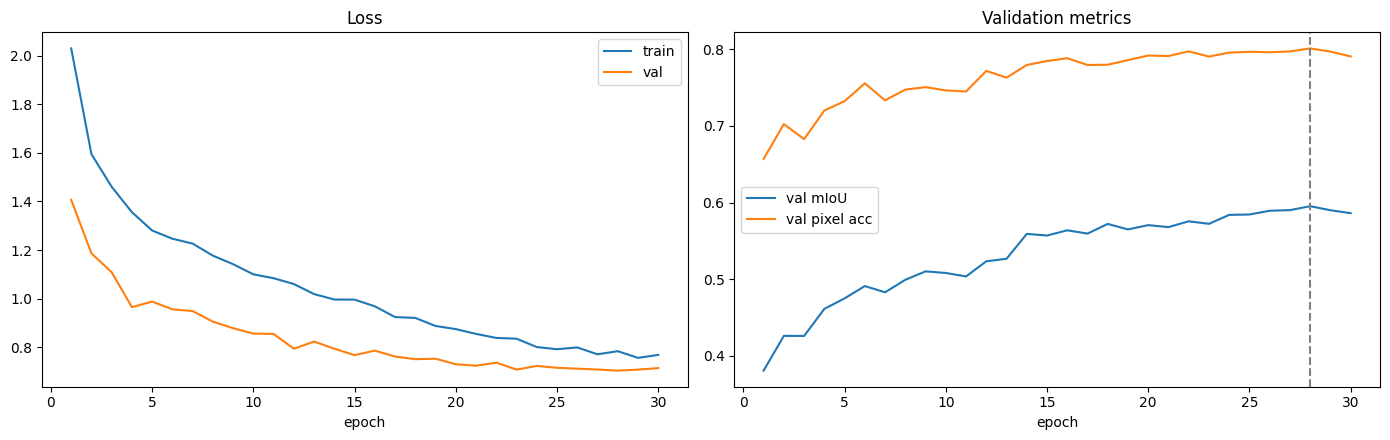

__notebook__.ipynb                2.2 MB
best_model.pth                  320.7 MB
class_weights.npz                 0.0 MB
dataset_info.json                 0.0 MB
history.csv                       0.0 MB
last_checkpoint.pth             320.7 MB
manifest.csv                      0.6 MB
training_config.json              0.0 MB


In [9]:
train_cfg = {**CFG, "num_classes": NUM_CLASSES, "classes": CLASSES, "image_size_wh": [IMG_W, IMG_H],
             "mean": MEAN, "std": STD, "best_epoch": best_epoch, "best_val_miou": best_miou,
             "epochs_run": len(history)}
(WORK_DIR / "training_config.json").write_text(json.dumps(train_cfg, indent=2))

h = pd.DataFrame(history)
if h.empty:
    print("No completed epochs in this run - nothing to plot.")
else:
  fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
  axes[0].plot(h.epoch, h.train_loss, label="train"); axes[0].plot(h.epoch, h.val_loss, label="val")
  axes[0].set_title("Loss"); axes[0].legend(); axes[0].set_xlabel("epoch")
  axes[1].plot(h.epoch, h.val_miou, label="val mIoU"); axes[1].plot(h.epoch, h.val_pixel_acc, label="val pixel acc")
  axes[1].axvline(best_epoch, ls="--", c="gray"); axes[1].set_title("Validation metrics"); axes[1].legend(); axes[1].set_xlabel("epoch")
  plt.tight_layout(); plt.show()

for p in sorted(WORK_DIR.iterdir()):
    if p.is_file():
        print(f"{p.name:28s} {p.stat().st_size / 1e6:8.1f} MB")

**Next:** *Save Version → Save & Run All*. In notebook 03 add **both** this notebook's output and notebook 01's output as inputs.